In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

df = pd.read_csv(r"/content/student_exam_performance.csv")

print("Dataset shape:", df.shape)  # Basic dataset check

duplicates = df.duplicated().sum()
print("Number of duplicate rows:", duplicates)

print("Number of duplicated student IDs:", df["student_id"].duplicated().sum())
print("Number of unique student IDs:", df["student_id"].nunique())

# Check the target before the split
print("\nMissing target values:")
print(df["pass_status"].isna().sum())

print("\nTarget classes:")
print(df["pass_status"].unique())

print("\nTarget distribution:")
print(df["pass_status"].value_counts())

print("\nTarget distribution (%):")
print(df["pass_status"].value_counts(normalize=True) * 100)

# Clean target values before encoding
df["pass_status"] = (
    df["pass_status"]
    .astype("string")
    .str.strip()
    .str.lower()
)

print("\nCleaned target classes:")
print(df["pass_status"].value_counts(dropna=False))

target_mapping = {
    "pass": 0,
    "fail": 1
}

df["pass_status"] = df["pass_status"].map(target_mapping)

print("\nEncoded target distribution:")
print(df["pass_status"].value_counts(dropna=False))

print("\nMissing values after target encoding:")
print(df["pass_status"].isna().sum())

# Remove the target, ID, and outcome-related columns
target_column = "pass_status"
leakage_columns = [
    "student_id",
    "exam_score",
    "performance_grade",
    "performance_level",
    "questions_attempted",
    "questions_correct"
]
X = df.drop(columns=[target_column] + leakage_columns)
y = df[target_column]

# Clean categorical values
categorical_columns = X.select_dtypes(include=["object", "string", "category"]).columns

for column in categorical_columns:
    X[column] = X[column].astype("string").str.strip().str.lower()

# Identify numerical and categorical columns
numerical_columns = X.select_dtypes(include=["int64", "float64"]).columns
categorical_columns = X.select_dtypes(include=["object", "string", "category"]).columns

print("\nNumerical columns:")
print(list(numerical_columns))

print("\nCategorical columns:")
print(list(categorical_columns))

# Split before imputation to prevent data leakage
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True))

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True))

# Check important numerical ranges for possible invalid values
columns_to_check = ["age", "previous_exam_score", "previous_gpa", "attendance_percentage", "assignment_completion_rate", "study_hours_per_day", "self_study_hours", "online_course_hours", "physical_activity_hours", "daily_screen_time"]

print("\nRange checks:")

for column in columns_to_check:
    if column in X_train.columns:
        print(column, "min =", X_train[column].min(), "max =", X_train[column].max())

# Fill numerical missing values using the training median
for column in numerical_columns:
    median_value = X_train[column].median()
    X_train[column] = X_train[column].fillna(median_value)
    X_test[column] = X_test[column].fillna(median_value)

# Fill categorical missing values using the training mode
for column in categorical_columns:
    mode_value = X_train[column].mode()[0]
    X_train[column] = X_train[column].fillna(mode_value)
    X_test[column] = X_test[column].fillna(mode_value)

print("\nMissing values after imputation:")
print("Training:", X_train.isnull().sum().sum())
print("Testing:", X_test.isnull().sum().sum())

# Convert categorical variables into 0/1 columns
X_train = pd.get_dummies(X_train, columns=categorical_columns, drop_first=True, dtype=int)
X_test = pd.get_dummies(X_test, columns=categorical_columns, drop_first=True, dtype=int)

# Make sure train and test have exactly the same features
X_test = X_test.reindex(columns=X_train.columns, fill_value=0)

print("\nShape after one-hot encoding:")
print("Training:", X_train.shape)
print("Testing:", X_test.shape)

# Keep unscaled data for tree-based models
# Create scaled copies for models that are sensitive to feature scale
X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()

# Standardize only the original numerical variables
scaler = StandardScaler()

scaler_columns = [column for column in numerical_columns if column in X_train.columns]

X_train_scaled[scaler_columns] = scaler.fit_transform(X_train[scaler_columns])
X_test_scaled[scaler_columns] = scaler.transform(X_test[scaler_columns])

# Final checks
print("\nPre-processing completed successfully.")

print("\nTraining data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

print("\nScaled training data shape:", X_train_scaled.shape)
print("Scaled testing data shape:", X_test_scaled.shape)

print("\nTarget variable distribution:")
print(y.value_counts())

print("\nMissing values in training data:")
print(X_train.isnull().sum().sum())

print("Missing values in testing data:")
print(X_test.isnull().sum().sum())

print("\nMissing values in scaled training data:")
print(X_train_scaled.isnull().sum().sum())

print("Missing values in scaled testing data:")
print(X_test_scaled.isnull().sum().sum())

print("\nFinal number of features:", X_train.shape[1])

Dataset shape: (100000, 44)
Number of duplicate rows: 0
Number of duplicated student IDs: 0
Number of unique student IDs: 100000

Missing target values:
0

Target classes:
['Pass' 'Fail']

Target distribution:
pass_status
Pass    77389
Fail    22611
Name: count, dtype: int64

Target distribution (%):
pass_status
Pass    77.389
Fail    22.611
Name: proportion, dtype: float64

Cleaned target classes:
pass_status
pass    77389
fail    22611
Name: count, dtype: Int64

Encoded target distribution:
pass_status
0    77389
1    22611
Name: count, dtype: int64

Missing values after target encoding:
0

Numerical columns:
['age', 'previous_exam_score', 'previous_gpa', 'attendance_percentage', 'assignment_completion_rate', 'study_hours_per_day', 'self_study_hours', 'private_tuition', 'online_learning_hours', 'practice_tests_completed', 'sleep_hours', 'daily_screen_time', 'physical_activity_hours', 'stress_level', 'internet_access', 'online_course_hours', 'exam_preparation_days', 'time_management_s

## 4. Machine Learning Model & Evaluation

This is a binary classification problem (Pass vs Fail). Below we train Random Forest and Gradient Boosting, tune them lightly, evaluate with standard classification metrics, inspect feature importance, and combine both models into an ensemble.

In [ ]:
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, VotingClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                              classification_report, confusion_matrix, ConfusionMatrixDisplay)
import matplotlib.pyplot as plt
import numpy as np

### Random Forest

Random Forest is a good baseline for tabular data since it handles mixed feature types and non-linear relationships without needing feature scaling, so we use the unscaled data.

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV

rf_params = {
    "n_estimators": [100, 200],
    "max_depth": [10, 20],
    "min_samples_leaf": [1, 3]
}

rf_grid = GridSearchCV(
    estimator=RandomForestClassifier(
        random_state=42,
        class_weight="balanced",
        n_jobs=1
    ),
    param_grid=rf_params,
    cv=3,
    scoring="f1",
    n_jobs=1,
    verbose=2
)

rf_grid.fit(X_train, y_train)

rf_model = rf_grid.best_estimator_

print("Best Random Forest parameters:")
print(rf_grid.best_params_)

print("\nBest Random Forest Cross-Validation F1:")
print(round(rf_grid.best_score_, 4))

Fitting 3 folds for each of 8 candidates, totalling 24 fits
[CV] END .max_depth=10, min_samples_leaf=1, n_estimators=100; total time=  11.0s
[CV] END .max_depth=10, min_samples_leaf=1, n_estimators=100; total time=  11.4s
[CV] END .max_depth=10, min_samples_leaf=1, n_estimators=100; total time=  11.3s
[CV] END .max_depth=10, min_samples_leaf=1, n_estimators=200; total time=  23.1s
[CV] END .max_depth=10, min_samples_leaf=1, n_estimators=200; total time=  24.9s
[CV] END .max_depth=10, min_samples_leaf=1, n_estimators=200; total time=  22.6s
[CV] END .max_depth=10, min_samples_leaf=3, n_estimators=100; total time=  11.3s
[CV] END .max_depth=10, min_samples_leaf=3, n_estimators=100; total time=  11.6s
[CV] END .max_depth=10, min_samples_leaf=3, n_estimators=100; total time=  11.4s
[CV] END .max_depth=10, min_samples_leaf=3, n_estimators=200; total time=  22.8s
[CV] END .max_depth=10, min_samples_leaf=3, n_estimators=200; total time=  22.2s
[CV] END .max_depth=10, min_samples_leaf=3, n_est

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    classification_report
)

rf_preds = rf_model.predict(X_test)
rf_prob = rf_model.predict_proba(X_test)[:, 1]

print("Random Forest Performance")
print("=" * 50)

print(
    "Accuracy:",
    round(accuracy_score(y_test, rf_preds), 4)
)

print(
    "Precision for Fail:",
    round(precision_score(y_test, rf_preds), 4)
)

print(
    "Recall for Fail:",
    round(recall_score(y_test, rf_preds), 4)
)

print(
    "F1 for Fail:",
    round(f1_score(y_test, rf_preds), 4)
)

print(
    "ROC-AUC:",
    round(roc_auc_score(y_test, rf_prob), 4)
)

print(
    "PR-AUC:",
    round(
        average_precision_score(y_test, rf_prob),
        4
    )
)

print()

print(
    classification_report(
        y_test,
        rf_preds,
        target_names=["Pass", "Fail"],
        zero_division=0
    )
)

Random Forest Performance
Accuracy: 0.795
Precision for Fail: 0.5314
Recall for Fail: 0.7888
F1 for Fail: 0.635
ROC-AUC: 0.8795
PR-AUC: 0.6936

              precision    recall  f1-score   support

        Pass       0.93      0.80      0.86     15478
        Fail       0.53      0.79      0.64      4522

    accuracy                           0.80     20000
   macro avg       0.73      0.79      0.75     20000
weighted avg       0.84      0.80      0.81     20000



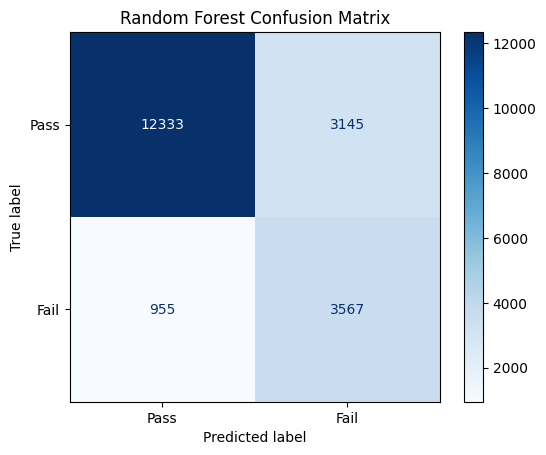

In [ ]:
rf_cm = confusion_matrix(y_test, rf_preds)
disp = ConfusionMatrixDisplay(confusion_matrix=rf_cm, display_labels=["Pass", "Fail"])
disp.plot(cmap="Blues")
plt.title("Random Forest Confusion Matrix")
plt.show()

### Feature Importance (Random Forest)

Feature importance shows which variables the model relied on most, which helps validate that the predictions make sense and aren't driven by noise.

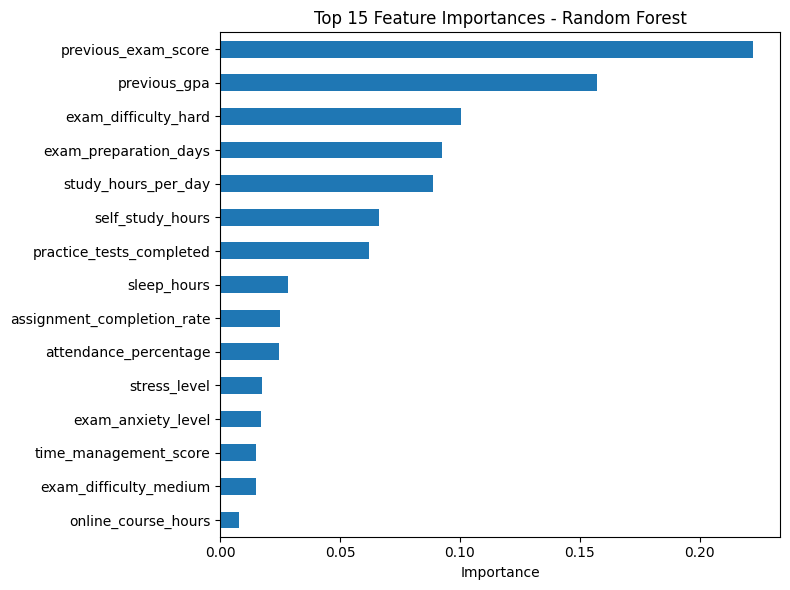

In [ ]:
importances = pd.Series(rf_model.feature_importances_, index=X_train.columns)
top_features = importances.sort_values(ascending=False).head(15)

plt.figure(figsize=(8, 6))
top_features.sort_values().plot(kind="barh")
plt.title("Top 15 Feature Importances - Random Forest")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

### Gradient Boosting

Gradient Boosting builds trees sequentially where each one corrects the errors of the previous one, often giving better accuracy than a single Random Forest at the cost of more training time.

### Ensemble Model (Random Forest + XGBoost)

Combining Random Forest and XGBoost through soft voting averages their predicted probabilities, which usually reduces variance and gives a more stable result than either model alone.

In [ ]:
from xgboost import XGBClassifier

xgb_model = XGBClassifier(
    n_estimators=300,
    max_depth=5,
    learning_rate=0.1,
    random_state=42,
    eval_metric="logloss"
)
xgb_model.fit(X_train, y_train)

ensemble_model = VotingClassifier(
    estimators=[("rf", rf_model), ("xgb", xgb_model)],
    voting="soft"
)
ensemble_model.fit(X_train, y_train)

ensemble_preds = ensemble_model.predict(X_test)

print("Ensemble (RF + XGBoost) Performance")
print("Accuracy:", accuracy_score(y_test, ensemble_preds))
print("Precision:", precision_score(y_test, ensemble_preds))
print("Recall:", recall_score(y_test, ensemble_preds))
print("F1-Score:", f1_score(y_test, ensemble_preds))
print()
print(classification_report(y_test, ensemble_preds))

Ensemble (RF + XGBoost) Performance
Accuracy: 0.84625
Precision: 0.6613154960981048
Recall: 0.6559044670499778
F1-Score: 0.6585988675474631

              precision    recall  f1-score   support

           0       0.90      0.90      0.90     15478
           1       0.66      0.66      0.66      4522

    accuracy                           0.85     20000
   macro avg       0.78      0.78      0.78     20000
weighted avg       0.85      0.85      0.85     20000



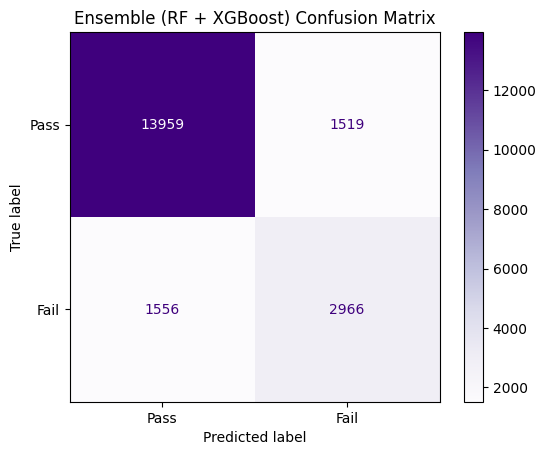

In [ ]:
ensemble_cm = confusion_matrix(y_test, ensemble_preds)
disp = ConfusionMatrixDisplay(confusion_matrix=ensemble_cm, display_labels=["Pass", "Fail"])
disp.plot(cmap="Purples")
plt.title("Ensemble (RF + XGBoost) Confusion Matrix")
plt.show()

### Model Comparison

In [ ]:
results = pd.DataFrame({
    "Model": ["Random Forest", "Ensemble (RF+XGB)"],
    "Accuracy": [accuracy_score(y_test, rf_preds), accuracy_score(y_test, ensemble_preds)],
    "Precision": [precision_score(y_test, rf_preds), precision_score(y_test, ensemble_preds)],
    "Recall": [recall_score(y_test, rf_preds), recall_score(y_test, ensemble_preds)],
    "F1-Score": [f1_score(y_test, rf_preds), f1_score(y_test, ensemble_preds)]
})

results

,Model,Accuracy,Precision,Recall,F1-Score
0,Random Forest,0.79500,0.531436,0.788810,0.635036
1,Ensemble (RF+XGB),0.84625,0.661315,0.655904,0.658599
